# Oscar — 02: logistic regression (working)

Run `report/01-Data.ipynb` first

Only `train` and `validation` are loaded here.

In [1]:
import pandas as pd

import prep                         # Oscar/prep.py: loading and fixes 1-4 from 01-eda.ipynb

X_train, y_train = prep.load("train")
X_val, y_val = prep.load("validation")

for name, y in [("train", y_train), ("validation", y_val)]:
    print(f"{name:<10} {len(y):,} customers, {y.mean():.2%} defaulted")

train      17,997 customers, 22.12% defaulted
validation 5,999 customers, 22.12% defaulted


Apply fixes 1–4 from `01-eda.ipynb`: repayment status and demographics as
categories, signed log of the amounts, then standardise. 

In [2]:
X_train, X_val = prep.transform(X_train, X_val)

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
X_train.head()

X_train: (17997, 50)   X_val: (5999, 50)


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,...,PAY_6_0,PAY_6_1,PAY_6_2,PAY_6_3,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
ID,,,,,,,,,,,,,,,,,,,,,
1,-1.879492,-1.243785,-0.193659,-0.185340,-0.531585,-2.118182,-2.039339,-1.921369,-2.030296,-0.009352,...,-1.089993,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
2,0.029578,-1.027394,-0.300176,-0.339332,-0.184367,-0.091751,-0.034399,0.000874,-2.030296,0.104095,...,-1.089993,0.0,3.147582,-0.108657,0.805782,1.081006,-0.446184,-0.125028,0.934308,-0.116012
4,-0.903219,0.162760,0.507403,0.534969,0.559881,0.448487,0.488696,0.524477,0.301417,0.318173,...,0.917437,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
5,-0.903219,2.326674,0.028979,-0.027034,0.478367,0.372952,0.386880,0.421201,0.301417,1.202172,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
6,-0.903219,0.162760,0.596305,0.579131,0.599747,0.353749,0.392885,0.432041,0.369835,0.285712,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,-0.925064,-0.446184,-0.125028,0.934308,-0.116012


## 1. Baseline

Try a few different metrics

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score

preds = {}      # model name -> validation probabilities

# define the helper function
def score(name, p_val):
    preds[name] = p_val
    print(f"{name:<22} AUC {roc_auc_score(y_val, p_val):.4f}   "
          f"log loss {log_loss(y_val, p_val):.4f}   "
          f"acc {accuracy_score(y_val, p_val > 0.5):.4f}")

In [4]:
# everyone gets the training default rate
score("base rate", np.full(len(y_val), y_train.mean()))

# plain logistic regression, sklearn defaults (note: C=1.0 L2 penalty is on by default)
base = LogisticRegression(max_iter=1000)
base.fit(X_train, y_train)
score("logistic (default)", base.predict_proba(X_val)[:, 1])

base rate              AUC 0.5000   log loss 0.5284   acc 0.7788


logistic (default)     AUC 0.7780   log loss 0.4284   acc 0.8248


## 2. Regularisation: C, L1 vs L2

L2 norm shrinks weights towards zero but none actually reach zero

L1 norm can actually push weights to zero which removes those covariates from the model.

5-fold CV on train only (validation not used for tuning).

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(5, shuffle=True, random_state=2026)
Cs = np.logspace(-4, 2, 13)      # 0.0001 ... 100; small C = strong penalty

rows = []
for penalty, l1_ratio in [("L2", 0), ("L1", 1)]:
    for C in Cs:
        m = LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
        rows.append({"penalty": penalty, "C": C,
                     "auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std(),
                     "logloss": -r["test_neg_log_loss"].mean()})

cv_res = pd.DataFrame(rows)
cv_res.round(4)

,penalty,C,auc,auc_sd,logloss
0,L2,0.0001,0.7645,0.0098,0.5659
1,L2,0.0003,0.7689,0.0103,0.4975
2,L2,0.0010,0.7705,0.0112,0.4544
3,L2,0.0032,0.7703,0.0119,0.4396
4,L2,0.0100,0.7697,0.0122,0.4367
5,L2,0.0316,0.7692,0.0124,0.4365
6,L2,0.1000,0.7688,0.0125,0.4367
7,L2,0.3162,0.7687,0.0126,0.4369
8,L2,1.0000,0.7686,0.0126,0.4370
9,L2,3.1623,0.7686,0.0126,0.4371


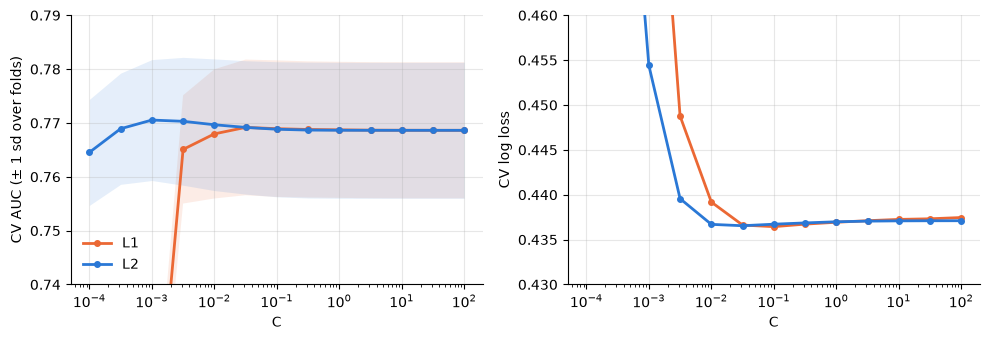

In [6]:
import matplotlib.pyplot as plt

colours = {"L2": "#2a78d6", "L1": "#eb6834"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
for penalty, d in cv_res.groupby("penalty"):
    ax1.plot(d["C"], d["auc"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
    ax1.fill_between(d["C"], d["auc"] - d["auc_sd"], d["auc"] + d["auc_sd"],
                     color=colours[penalty], alpha=0.12, lw=0)
    ax2.plot(d["C"], d["logloss"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
ax1.set(xscale="log", xlabel="C", ylabel="CV AUC (± 1 sd over folds)", ylim=(0.74, 0.79))
ax2.set(xscale="log", xlabel="C", ylabel="CV log loss", ylim=(0.43, 0.46))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax1.legend(frameon=False)
plt.tight_layout()

Pick best C per penalty by CV log loss, refit on all of train, check on validation.

In [7]:
best = cv_res.loc[cv_res.groupby("penalty")["logloss"].idxmin()]
print(best.round(4).to_string(index=False), "\n")

models = {}
for _, row in best.iterrows():
    l1_ratio = 1 if row["penalty"] == "L1" else 0
    m = LogisticRegression(C=row["C"], l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
    m.fit(X_train, y_train)
    models[row["penalty"]] = m
    score(f"{row['penalty']} C={row['C']:.3g}", m.predict_proba(X_val)[:, 1])

# which features did L1 drop?
coefs = pd.Series(models["L1"].coef_[0], index=X_train.columns)
print(f"\nL1 kept {(coefs != 0).sum()} of {len(coefs)}; dropped:", list(coefs[coefs == 0].index))

penalty      C    auc  auc_sd  logloss
     L1 0.1000 0.7689  0.0127   0.4364
     L2 0.0316 0.7692  0.0124   0.4365 

L1 C=0.1               AUC 0.7782   log loss 0.4285   acc 0.8255
L2 C=0.0316            AUC 0.7783   log loss 0.4284   acc 0.8251

L1 kept 44 of 50; dropped: ['BILL_AMT2', 'PAY_5_-2', 'PAY_5_0', 'PAY_5_1', 'PAY_6_0', 'PAY_6_1']


### What we have seen so far

1. Logistic regression is clearly an improvement over just flipping a coin (guessing). AUC goes from 0.5 to 0.778 and log loss decreases from 0.528 to 0.428
2. Accuracy is an inapropraite metric for the data. note if we were to just predict that nobody defaults then we immediately get 77/.9% accuracy
3. Regularisation makes relatively little difference which is in some way reassuring, this implies that we were not previously overfitting on the training data.
4. The limit seems to be the sigmoid curve itself, look ahead to SVM...

## 2. Investigating the limits of the current model

### Learning curve

Would more data help? Train vs CV AUC as the training set grows.

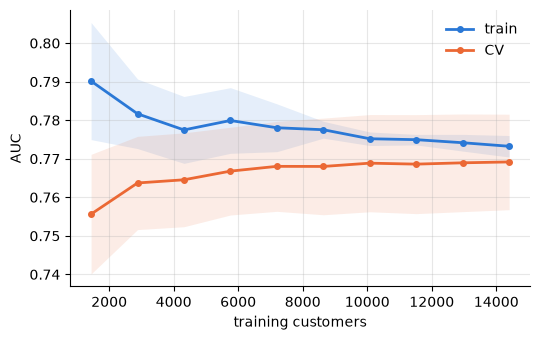

In [8]:
from sklearn.model_selection import learning_curve

final = models["L2"]        # L2, C=0.0316 from above
sizes, auc_tr, auc_cv = learning_curve(final, X_train, y_train, cv=cv, scoring="roc_auc",
                                       train_sizes=np.linspace(0.1, 1, 10),
                                       shuffle=True, random_state=2026)   # rows are in ID order, see check below

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name, s, c in [("train", auc_tr, "#2a78d6"), ("CV", auc_cv, "#eb6834")]:
    ax.plot(sizes, s.mean(1), "o-", color=c, lw=2, ms=4, label=name)
    ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=0.12, lw=0)
ax.set(xlabel="training customers", ylabel="AUC")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

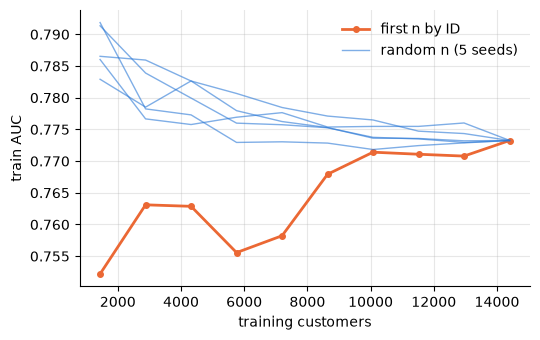

In [9]:
# check: without shuffle, each subset is the first n customers by ID; with shuffle, a random n
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for seed in [None, 0, 1, 2, 3, 4]:
    kw = {} if seed is None else {"shuffle": True, "random_state": seed}
    sz, tr, _ = learning_curve(final, X_train, y_train, cv=cv, scoring="roc_auc",
                               train_sizes=np.linspace(0.1, 1, 10), **kw)
    if seed is None:
        ax.plot(sz, tr.mean(1), "o-", color="#eb6834", lw=2, ms=4, label="first n by ID")
    else:
        ax.plot(sz, tr.mean(1), color="#2a78d6", lw=1, alpha=0.6,
                label="random n (5 seeds)" if seed == 0 else None)
ax.set(xlabel="training customers", ylabel="train AUC")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

### What this shows

Train and CV converge at ~0.77 and the CV line flattens, so more data would not give a significant increase in performance. The model does appear to be too simple.

The dip in the unshuffled train curve is not noise. Data is in ID order, so it trained on the lowest IDs only. With random subsets (5 seeds) there is no dip

### Coefficients

What is the model using? (L2 model, features standardised)

,coef,odds ratio
PAY_1_2,0.435,1.544
PAY_1_0,-0.346,0.707
PAY_AMT2,-0.182,0.834
LIMIT_BAL,-0.181,0.834
BILL_AMT3,0.147,1.158
EDUCATION_4,-0.140,0.869
PAY_1_3,0.140,1.150
PAY_3_0,0.132,1.141
PAY_AMT1,-0.130,0.878
PAY_3_2,0.127,1.135


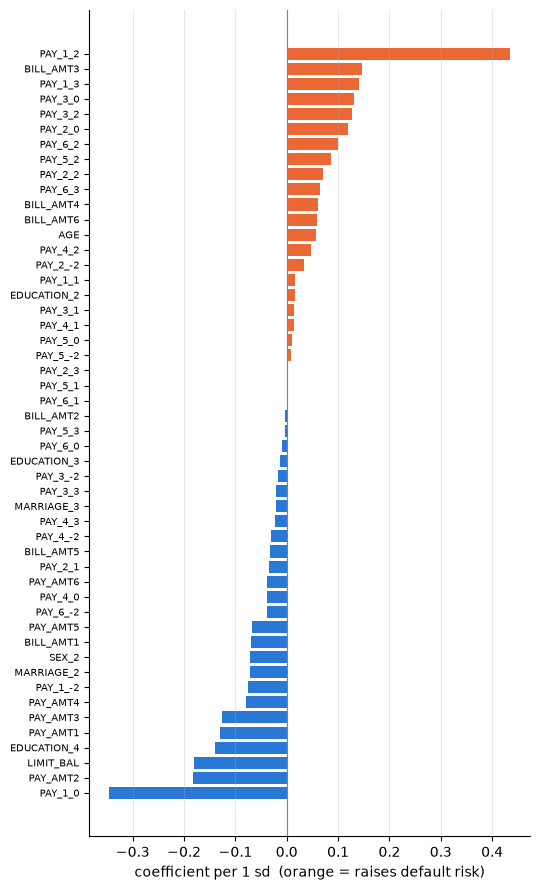

In [10]:
coef = pd.Series(final.coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(5.5, 9))
ax.barh(coef.index, coef, color=np.where(coef > 0, "#eb6834", "#2a78d6"))
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="coefficient per 1 sd  (orange = raises default risk)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# 10 largest effects; odds ratio = factor on the odds of default per 1 sd
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:10]
pd.DataFrame({"coef": top, "odds ratio": np.exp(top)}).round(3)

### Reading the coefficients

Logistic regression is a GLM with a logit link, so the linear predictor is on the log-odds scale:

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_{50} x_{50}$$

- $\beta_j > 0$ raises the risk of default, $\beta_j < 0$ lowers it.
- $e^{\beta_j}$ is an odds ratio: the factor the odds of default are multiplied by per unit of $x_j$, holding the other features fixed.
- Because the features are standardised, one unit = 1 sd. So the coefficients are on a common scale and can be compared directly. Without this, a coefficient on LIMIT_BAL (log NT$) and one on AGE (years) would not be comparable.
- Caveat for 0/1 dummies: "per 1 sd" is less natural. To get the effect vs the reference category, use $\beta_j / \text{sd}_j$. E.g. `PAY_1_2`: sd ≈ 0.284, so $0.435 / 0.284 ≈ 1.53$ and $e^{1.53} ≈ 4.6$. Being 2 months late multiplies the odds of default by ~4.6 vs paying in full.

It's worth noting here the meaning behind a coefficient in logistic regression. The exponential of the coefficient shows the multiplicative change in the odds when that covariate moves by one unit - **with all other covariates fixed**. This is answering a fundamentally different question to partitioning the raw data via a covariate, thus we have to be slightly careful in how we interpret the coefficients. In our case, having even two customers who are identical in all but one covariate is very unlikely. Therefore it is important to read groups of closely linked covariates together (e.g. the six months of repayment status, or the six bill amounts), rather than reading too much into any single coefficient. For example, partitioning the raw data by `PAY_1_2` gives odds of default about 10 times higher for customers 2 months late than for those who paid in full (69% vs 18%), but the model only attributes ×4.6 to `PAY_1_2` itself.

### How well is the model calibrated

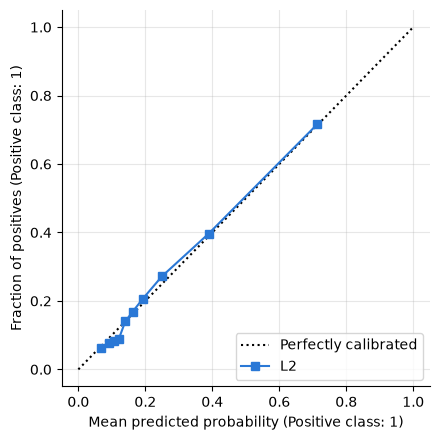

In [11]:
from sklearn.calibration import CalibrationDisplay

p_val = final.predict_proba(X_val)[:, 1]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
CalibrationDisplay.from_predictions(y_val, p_val, n_bins=10, strategy="quantile",   # 10 bins of ~600 customers
                                    ax=ax, name="L2", color="#2a78d6")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### What this shows

- Points sit almost on the diagonal: top bin predicts 71%, 72% actually default. So the probabilities can be taken at face value.
- Calibration ≠ AUC. AUC only checks ranking; this checks the numbers themselves.
- Most predictions are below 0.25, hence quantile bins (~600 customers each).
- The small wiggles around 0.1 are within noise (±~1.6 pts per bin).
- Expected for LR: max likelihood = minimising log loss. Forests may not be this good, so compare later.
- The top bin lumps together everyone from roughly the top 10% up, so the high-risk tail isn't checked in much detail.
- Good for choosing a threshold later: we can use the probabilities directly.

## 3.  Increasing model complexity by introducing more features

Same 5-fold CV and same model (L2, C=0.0316) for every feature set; validation untouched.

In [12]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raw_train, _ = prep.load("train")      # untransformed, for building new features
results, fold_auc = {}, {}             # name -> CV summary; name -> AUC on each fold

def cv_features(name, make=None):
    """5-fold CV of the tuned L2 model on prep's fixes plus any extra columns from make(raw)."""
    X = raw_train if make is None else make(raw_train.copy())
    X = prep.prepare(X)                                      # fixes 1-3: fixed rules, nothing learned
    model = make_pipeline(StandardScaler(), clone(final))    # fix 4 learned inside each fold
    r = cross_validate(model, X, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
    fold_auc[name] = r["test_roc_auc"]
    results[name] = {"n": X.shape[1],
                     "auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std(),
                     "logloss": -r["test_neg_log_loss"].mean()}
    return pd.DataFrame.from_dict(results, orient="index").round(4)

cv_features("base")

,n,auc,auc_sd,logloss
base,50,0.769,0.0125,0.4367


We will now use the above function to test the introduction of new features. We start from the raw data (log has not been applied yet) then add in the new features and then apply the cleanup from `prep.py`. We then test for any potential improvement in the model via CV.

### Ratio features

- Utilisation = bill / credit limit, each of the 6 months. How close to their limit someone is.
- Pay ratio = payment / previous month's bill, clipped to [0, 1]. Did they pay it off or just the minimum? Set to 1 if nothing was owed.

In [13]:
def add_util(df):
    for k in range(1, 7):
        df[f"UTIL_{k}"] = (df[f"BILL_AMT{k}"] / df["LIMIT_BAL"]).clip(upper=1.5)   # a few go up to ~10
    return df

def add_payratio(df):
    for k in range(1, 6):
        bill, paid = df[f"BILL_AMT{k+1}"], df[f"PAY_AMT{k}"]      # PAY_AMTk pays last month's bill
        df[f"PAYRATIO_{k}"] = (paid / bill).where(bill > 0, 1).clip(0, 1)   # nothing owed -> 1
    return df

cv_features("+ utilisation", add_util)
cv_features("+ pay ratio", add_payratio)
cv_features("+ both", lambda df: add_payratio(add_util(df)))

,n,auc,auc_sd,logloss
base,50,0.7690,0.0125,0.4367
+ utilisation,56,0.7717,0.0140,0.4361
+ pay ratio,55,0.7707,0.0129,0.4360
+ both,61,0.7722,0.0140,0.4358


In [14]:
def compare(ref="base"):
    """AUC gain over `ref`, fold by fold: every feature set sat the same 5 folds."""
    gain = pd.DataFrame(fold_auc).sub(fold_auc[ref], axis=0)
    return pd.DataFrame({"mean gain": gain.mean(), "folds better": (gain > 0).sum()}).round(4)

compare()

,mean gain,folds better
base,0.0000,0
+ utilisation,0.0027,4
+ pay ratio,0.0017,5
+ both,0.0032,5


### Trends across the 6 months

On top of the ratios. Two kinds:
- Linear trends (months late, change in utilisation): these are sums/differences of columns the model already has, so LR can already build them. Expect no gain.
- Summaries (worst month, current late streak, max and spread of utilisation, months paid off): not linear in the existing columns, so they could add something.

In [15]:
STATUS = [f"PAY_{k}" for k in range(1, 7)]        # month 1 = most recent
UTIL = [f"UTIL_{k}" for k in range(1, 7)]
PAYRATIO = [f"PAYRATIO_{k}" for k in range(1, 6)]

def add_linear_trends(df):
    df = add_payratio(add_util(df))
    df["N_LATE"] = (df[STATUS] >= 1).sum(axis=1)                 # months late out of 6
    df["UTIL_CHANGE"] = df["UTIL_1"] - df["UTIL_6"]              # utilisation rising?
    return df

def add_summaries(df):
    df = add_payratio(add_util(df))
    late = df[STATUS] >= 1
    df["MAX_STATUS"] = df[STATUS].max(axis=1).clip(upper=3)      # worst month
    df["LATE_STREAK"] = late.cumprod(axis=1).sum(axis=1)         # months late in a row, counting back from now
    df["UTIL_MAX"] = df[UTIL].max(axis=1)
    df["UTIL_SD"] = df[UTIL].std(axis=1)                         # how much utilisation jumps around
    df["N_FULLPAY"] = (df[PAYRATIO] >= 1).sum(axis=1)            # months the bill was paid off
    return df

cv_features("+ both + linear trends", add_linear_trends)
cv_features("+ both + summaries", add_summaries)

,n,auc,auc_sd,logloss
base,50,0.7690,0.0125,0.4367
+ utilisation,56,0.7717,0.0140,0.4361
+ pay ratio,55,0.7707,0.0129,0.4360
+ both,61,0.7722,0.0140,0.4358
+ both + linear trends,63,0.7722,0.0140,0.4358
+ both + summaries,66,0.7731,0.0129,0.4347


In [16]:
compare("+ both")

,mean gain,folds better
base,-0.0032,0
+ utilisation,-0.0005,0
+ pay ratio,-0.0016,1
+ both,0.0000,0
+ both + linear trends,-0.0000,1
+ both + summaries,0.0009,3


### Decision

Keep the ratios ("+ both": 0.7722, better than base on 5/5 folds). Drop the trends: linear trends add nothing (LR can already build them), and the summaries give +0.0009 on only 3/5 folds, which isn't worth 5 extra columns.

## 4. Final model

In [17]:
# C was tuned without the ratios; re-check it with them (same folds, scaling inside each fold)
X_ratio = prep.prepare(raw_train, ratios=True)

rows = []
for C in np.logspace(-3, 0, 7):
    model = make_pipeline(StandardScaler(), clone(final).set_params(C=C))
    r = cross_validate(model, X_ratio, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
    rows.append({"C": C, "auc": r["test_roc_auc"].mean(), "logloss": -r["test_neg_log_loss"].mean()})

tune = pd.DataFrame(rows)
best_C = tune.loc[tune["logloss"].idxmin(), "C"]
print(f"best C = {best_C:.3g}")
tune.round(4)

best C = 0.0316


,C,auc,logloss
0,0.0010,0.7744,0.4531
1,0.0032,0.7737,0.4385
2,0.0100,0.7729,0.4358
3,0.0316,0.7722,0.4358
4,0.1000,0.7719,0.4360
5,0.3162,0.7717,0.4362
6,1.0000,0.7717,0.4364


In [18]:
# final model: L2 + ratios, fitted on train only; validation as a check
X_test_raw, y_test = prep.load("test")
Xf_train, Xf_val, Xf_test = prep.transform(raw_train, prep.load("validation")[0], X_test_raw, ratios=True)

final_model = clone(final).set_params(C=best_C).fit(Xf_train, y_train)
score("logistic (default)", preds["logistic (default)"])
score(f"L2 + ratios C={best_C:.3g}", final_model.predict_proba(Xf_val)[:, 1])

logistic (default)     AUC 0.7780   log loss 0.4284   acc 0.8248
L2 + ratios C=0.0316   AUC 0.7816   log loss 0.4267   acc 0.8243


In [19]:
# test set: used once, after every choice above was made
p_test = final_model.predict_proba(Xf_test)[:, 1]
print(f"test       AUC {roc_auc_score(y_test, p_test):.4f}   log loss {log_loss(y_test, p_test):.4f}   "
      f"({len(y_test):,} customers, {y_test.mean():.2%} defaulted)")

# probabilities for the group's metric notebook (join to the labels on ID)
out = prep.ROOT / "data" / "output" / "predictions-logistic.csv"
pd.DataFrame({"p_default": p_test}, index=Xf_test.index).to_csv(out)
print("saved", out.relative_to(prep.ROOT))

test       AUC 0.7872   log loss 0.4302   (5,999 customers, 22.12% defaulted)
saved data/output/predictions-logistic.csv


,coef,odds ratio,coef without ratios
PAY_1_2,0.405,1.499,0.435
PAY_1_0,-0.380,0.684,-0.346
PAYRATIO_2,-0.152,0.859,NaN
PAY_4_0,-0.142,0.868,-0.039
EDUCATION_4,-0.142,0.868,-0.140
PAY_AMT2,-0.134,0.874,-0.182
PAY_1_3,0.129,1.137,0.140
LIMIT_BAL,-0.126,0.881,-0.181
PAY_AMT3,-0.106,0.899,-0.126
PAYRATIO_3,-0.105,0.900,NaN


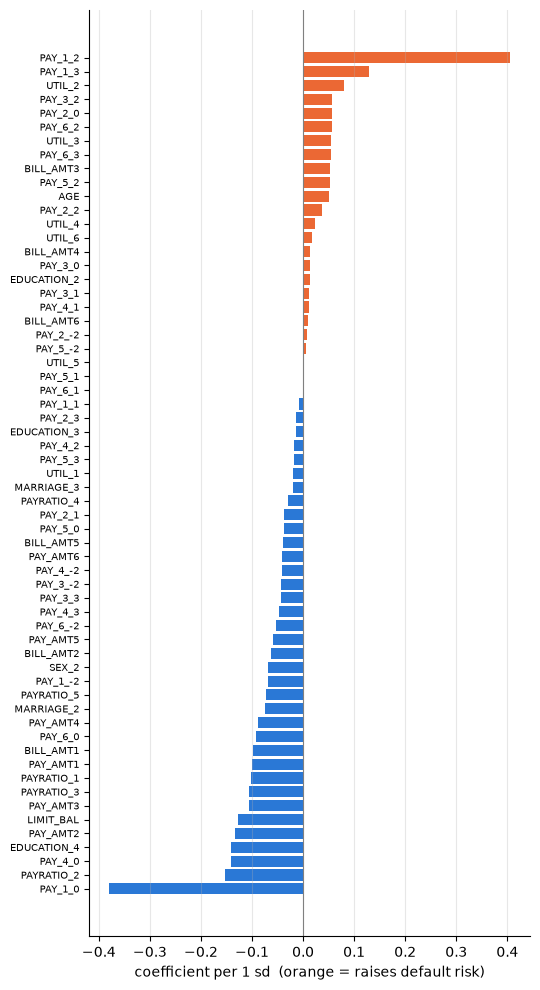

In [20]:
# coefficients of the final model (features standardised, so per 1 sd)
coef_f = pd.Series(final_model.coef_[0], index=Xf_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(5.5, 10))
ax.barh(coef_f.index, coef_f, color=np.where(coef_f > 0, "#eb6834", "#2a78d6"))
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="coefficient per 1 sd  (orange = raises default risk)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# 12 largest effects, next to the same column in the model without ratios (blank = new column)
top_f = coef_f.reindex(coef_f.abs().sort_values(ascending=False).index)[:12]
pd.DataFrame({"coef": top_f, "odds ratio": np.exp(top_f),
              "coef without ratios": coef.reindex(top_f.index)}).round(3)

In [ ]:
# PAY_1_2 against the reference (PAY_1 = -1, paid on time): the model's effect, then the raw data
sd = X_ratio["PAY_1_2"].std(ddof=0)          # the sd StandardScaler divided by
b = coef_f["PAY_1_2"]
print(f"PAY_1_2: coef {b:.3f}, sd {sd:.3f}, coef / sd {b / sd:.2f}, odds ratio {np.exp(b / sd):.1f}")

rate = y_train.groupby(raw_train["PAY_1"].clip(upper=3)).mean()
odds = rate / (1 - rate)
print(f"raw data: {rate[2]:.1%} default when 2 months late vs {rate[-1]:.1%} when paid on time, "
      f"odds ratio {odds[2] / odds[-1]:.1f}")

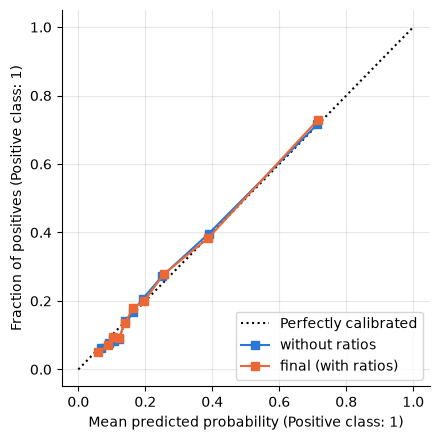

In [21]:
# calibration on validation: final model vs the model without ratios
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for name, p, c in [("without ratios", p_val, "#2a78d6"),
                   ("final (with ratios)", final_model.predict_proba(Xf_val)[:, 1], "#eb6834")]:
    CalibrationDisplay.from_predictions(y_val, p, n_bins=10, strategy="quantile", ax=ax, name=name, color=c)
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [ ]:
# the numbers behind the final model's calibration curve
from sklearn.calibration import calibration_curve

pf_val = final_model.predict_proba(Xf_val)[:, 1]
obs, pred = calibration_curve(y_val, pf_val, n_bins=10, strategy="quantile")
se = np.sqrt(obs * (1 - obs) / (len(y_val) / 10))      # binomial noise per bin of ~600
print(f"{(pf_val < 0.25).mean():.1%} of predictions below 0.25; top bin starts at {np.quantile(pf_val, 0.9):.2f}")
pd.DataFrame({"predicted": pred, "observed": obs, "gap": obs - pred,
              "noise (1 se)": se, "gap / se": (obs - pred) / se}).round(3)

## Summary

- Logistic regression has a clear performance improvement over the base rate
- Accuracy is misleading
- Regularisation doesnt change much
- The learning curve shows that logistic regression is too simple for the data
- Model is well calibrated
- Added two extra ratios as covariates which have marginally improved performance
- Worth noting that we havent played around with the treshold here, although seeing as this would not impact the AUC or log loss we are happy to continue to look ahead to SVMs from here

Looking ahead to SVM:
- worth bringing in the ratios
- the limit was the sigmoid shape, hopefully SVM can learn an interesting non-linear decisoin boundary via kernel trick